In [29]:
import os, sys

try:
  os.chdir('../Rで学ぶベイズ統計学入門')
except:
  pass

path = os.getcwd()

In [30]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib


from scipy.stats import beta, binom, betabinom, norm, t


In [31]:
print("Python:", sys.executable)

Python: /Users/takanohiroshi/myenv/bin/python


In [32]:
df = pd.read_csv('marathontimes.csv')

### 4.2 パラメータが二つとも未知の正規データ

20人のマラソンランナーのタイムが分単位で $ y_1, y_2,... y_{20} $ で $ N(\mu, \sigma) $ 分布に従うランダム標本とする。

標準的な無情報事前分布 $ g(\mu, \sigma^2) \propto 1/\sigma^2 $ を仮定する。

この場合の平均と分散の事後密度を求め、グラフを作成する。



標本数 n = 20
標本平均 x̄ = 277.6
平方和 S = 46626.799999999996


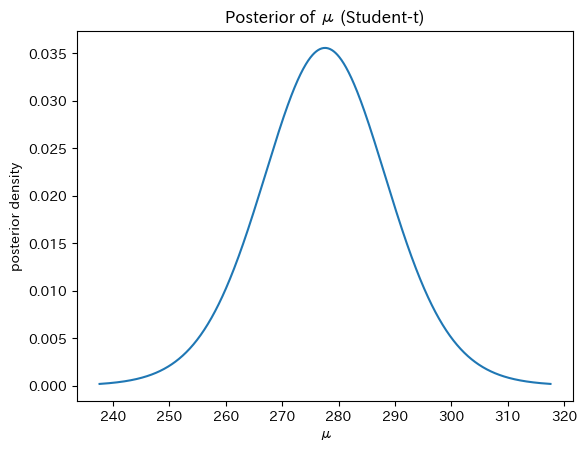

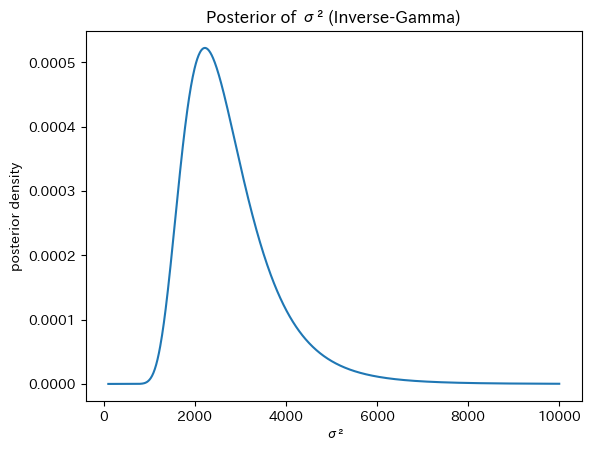

In [33]:
from scipy.stats import invgamma, t

# データ
x = df['time'].values

n = len(x)
xbar = np.mean(x)
S = np.sum((x - xbar)**2)

print("標本数 n =", n)
print("標本平均 x̄ =", xbar)
print("平方和 S =", S)

# -----------------------------
# (1) σ^2 の事後分布（逆ガンマ）
# -----------------------------
alpha = (n - 1) / 2
beta = S / 2

sigma2_grid = np.linspace(100, 10000, 1000)
posterior_sigma2 = invgamma.pdf(sigma2_grid, a=alpha, scale=beta)

# -----------------------------
# (2) μ の事後分布（t分布）
# -----------------------------
df = n - 1
scale_mu = np.sqrt(S / (n * (n - 1)))

mu_grid = np.linspace(xbar - 40, xbar + 40, 1000)
posterior_mu = t.pdf(mu_grid, df=df, loc=xbar, scale=scale_mu)

# -----------------------------
# グラフ描画
# -----------------------------
plt.figure()
plt.plot(mu_grid, posterior_mu)
plt.xlabel("μ")
plt.ylabel("posterior density")
plt.title("Posterior of μ (Student-t)")
plt.show()

plt.figure()
plt.plot(sigma2_grid, posterior_sigma2)
plt.xlabel("σ²")
plt.ylabel("posterior density")
plt.title("Posterior of σ² (Inverse-Gamma)")
plt.show()


In [34]:
n = len(x)
xbar = np.mean(x)
S = np.sum((x - xbar)**2)

# -----------------------------
# (1) 平均 μ の 95% 信用区間
# -----------------------------
df = n - 1
scale_mu = np.sqrt(S / (n * (n - 1)))

mu_lower, mu_upper = t.interval(
    0.95, df=df, loc=xbar, scale=scale_mu
)

# -----------------------------
# (2) 標準偏差 σ の 95% 信用区間
# -----------------------------
alpha = (n - 1) / 2
beta = S / 2

# σ^2 の区間
sigma2_lower, sigma2_upper = invgamma.interval(
    0.95, a=alpha, scale=beta
)

# σ に変換
sigma_lower = np.sqrt(sigma2_lower)
sigma_upper = np.sqrt(sigma2_upper)

# -----------------------------
# 結果表示
# -----------------------------
print("標本平均 x̄ =", xbar)
print("")

print("平均 μ の 95% 信用区間:")
print(f"({mu_lower:.2f}, {mu_upper:.2f})")

print("")
print("標準偏差 σ の 95% 信用区間:")
print(f"({sigma_lower:.2f}, {sigma_upper:.2f})")


標本平均 x̄ = 277.6

平均 μ の 95% 信用区間:
(254.42, 300.78)

標準偏差 σ の 95% 信用区間:
(37.67, 72.35)


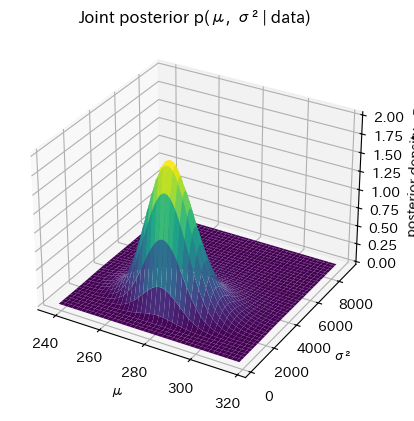

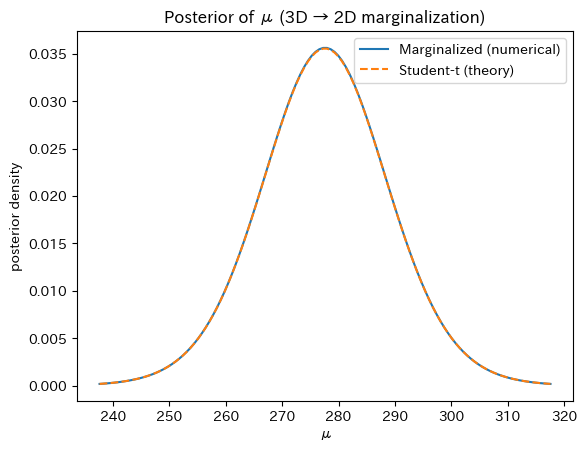

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import invgamma, norm, t
from mpl_toolkits.mplot3d import Axes3D

# -----------------------------
# データ
# -----------------------------
x = np.array([182, 201, 221, 234, 237, 251, 261, 266, 267, 273,
              286, 291, 292, 296, 296, 296, 326, 352, 359, 365])

n = len(x)
xbar = np.mean(x)
S = np.sum((x - xbar)**2)

# -----------------------------
# グリッド作成
# -----------------------------
mu_grid = np.linspace(xbar - 40, xbar + 40, 120)
sigma2_grid = np.linspace(200, 9000, 120)

MU, SIG2 = np.meshgrid(mu_grid, sigma2_grid)

# -----------------------------
# 同時事後分布 p(mu, sigma^2 | x)
# -----------------------------
# p(mu | sigma^2, x)
p_mu_given_sig2 = norm.pdf(
    MU,
    loc=xbar,
    scale=np.sqrt(SIG2 / n)
)

# p(sigma^2 | x)
alpha = (n - 1) / 2
beta = S / 2
p_sig2 = invgamma.pdf(SIG2, a=alpha, scale=beta)

# 同時事後
posterior_joint = p_mu_given_sig2 * p_sig2

# -----------------------------
# 3Dプロット（同時事後分布）
# -----------------------------
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(MU, SIG2, posterior_joint, cmap="viridis")
ax.set_xlabel("μ")
ax.set_ylabel("σ²")
ax.set_zlabel("posterior density")
ax.set_title("Joint posterior p(μ, σ² | data)")
plt.show()

# -----------------------------
# 周辺化（σ²方向に数値積分）
# -----------------------------
posterior_mu_marginal = np.trapz(posterior_joint, sigma2_grid, axis=0)

# 正規化
posterior_mu_marginal /= np.trapz(posterior_mu_marginal, mu_grid)

# 理論的な t 分布
df = n - 1
scale_mu = np.sqrt(S / (n * (n - 1)))
posterior_mu_theory = t.pdf(mu_grid, df=df, loc=xbar, scale=scale_mu)

# -----------------------------
# 2Dプロット（周辺事後分布）
# -----------------------------
plt.figure()
plt.plot(mu_grid, posterior_mu_marginal, label="Marginalized (numerical)")
plt.plot(mu_grid, posterior_mu_theory, "--", label="Student-t (theory)")
plt.xlabel("μ")
plt.ylabel("posterior density")
plt.title("Posterior of μ (3D → 2D marginalization)")
plt.legend()
plt.show()


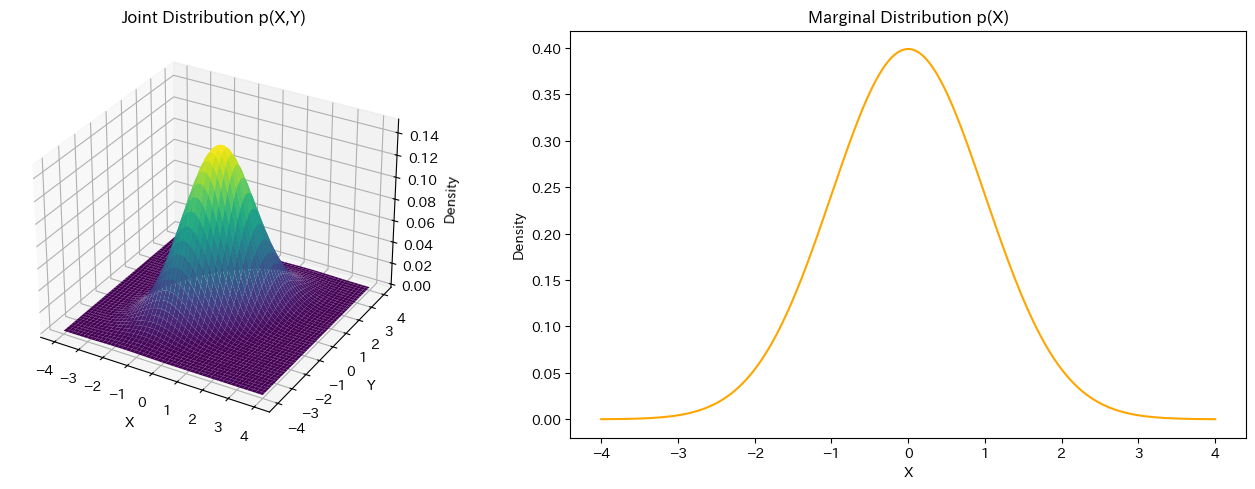

In [36]:
from scipy.stats import multivariate_normal

# --２次元ガウス分布の設定
mean = [0,0]
cov = [[1.0,0.6],[0.6,1.5]]

# --グリッドを作成
x = np.linspace(-4,4,200)
y = np.linspace(-4,4,200)
X, Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

# --同時分布 p(x,y)
rv = multivariate_normal(mean, cov)
joint_pdf = rv.pdf(pos)

# --周辺化
merginal_x = np.trapz(joint_pdf,y, axis=0)

# --可視化
fig = plt.figure(figsize=(14,5))

# 1.同時分布
ax1 = fig.add_subplot(1,2,1, projection='3d')
ax1.plot_surface(X,Y, joint_pdf, cmap='viridis')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Density')
ax1.set_title('Joint Distribution p(X,Y)')

# 2.周辺分布
ax2 = fig.add_subplot(1,2,2)
ax2.plot(x, merginal_x, color='orange')
ax2.set_xlabel('X')
ax2.set_ylabel('Density')   
ax2.set_title('Marginal Distribution p(X)')

plt.tight_layout()